# Recursive feature elimination with cross-validation

Compare native Moxie and scikit-learn on the gallery's 500-row, eight-class dataset with three informative and two redundant features. Both fit default logistic regression, remove one feature at a time, and use five unshuffled stratified folds to choose the number of features by accuracy.

Moxie wraps the estimator in `LogisticRegressionImportance` and uses the classifier's default accuracy scorer through `DenseSupervisedCV`. Moxie runs the folds serially.

Adapted from the scikit-learn developers' [RFECV gallery example](https://github.com/scikit-learn/scikit-learn/blob/4358542a1bd39af2e7e1cbace8b9fed067473c5b/examples/feature_selection/plot_rfe_with_cross_validation.py) (BSD-3-Clause).

In [1]:
import json
from pathlib import Path
import sys

import numpy as np
import sklearn
from sklearn.datasets import make_classification
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks/_support/moxie_nb.py").exists())
oracle = ROOT / "families/ensemble/builds/oracle-env"
receipt = ROOT / "families/ensemble/docs/private/forest_engine/oracle-build.json"
if oracle not in Path(sklearn.__file__).resolve().parents:
    raise RuntimeError("Use the pinned oracle environment described in docs/feature_selection/classifier-selection.md")
assert json.loads(receipt.read_text())["revision"] == "4358542a1bd39af2e7e1cbace8b9fed067473c5b"

sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("feature_selection/plot_rfe_with_cross_validation")

X, y = make_classification(
    n_samples=500, n_features=15, n_informative=3, n_redundant=2,
    n_repeated=0, n_classes=8, n_clusters_per_class=1,
    class_sep=0.8, random_state=0,
)
y = y.astype(np.int64)
feature_names = np.array([f"feature_{i}" for i in range(X.shape[1])])
reference = RFECV(
    LogisticRegression(), step=1, cv=StratifiedKFold(5),
    scoring="accuracy", min_features_to_select=1, n_jobs=2,
).fit(X, y)

nb.share(X=X, y=y, feature_names=feature_names)

In [2]:
%%mojo rfecv
import numojo as nm
from moxie.feature_selection import (
    DenseSupervisedCV,
    LogisticRegressionImportance,
    RFECV,
    SequentialCV,
)
from moxie.linear_model import LogisticRegression
from moxie_nb_io import load, load_strings, save, save_ints, save_strings


def main() raises:
    var X = load("X")
    var y = load[DType.int64]("y")
    var feature_names = load_strings("feature_names")
    comptime Estimator = LogisticRegressionImportance[]
    var estimator = LogisticRegressionImportance(LogisticRegression())
    var selector = RFECV[DenseSupervisedCV[Estimator]](estimator^, cv=SequentialCV(5))
    _ = selector.fit(X, y)

    save_ints("n_selected", [selector.n_features_()])
    save_ints("ranking", selector.ranking_())
    save_strings("selected_names", selector.get_feature_names_out(feature_names))
    save("transformed", selector.transform(X))
    save("predictions", selector.predict(X))

    var results = selector.cv_results_()
    var counts = results["n_features"][List[Int]].copy()
    save_ints("n_features", counts)
    for key in ["mean_test_score", "std_test_score"]:
        save(key, results[key][nm.NDArray[DType.float64]])
    for fold in range(5):
        var prefix = String("split", fold)
        save(prefix + "_test_score", results[prefix + "_test_score"][nm.NDArray[DType.float64]])
        var support = results[prefix + "_support"][List[List[Bool]]].copy()
        var ranking = results[prefix + "_ranking"][List[List[Int]]].copy()
        var masks = nm.zeros[DType.bool](nm.Shape(len(counts), X.shape[1]))
        var ranks = nm.zeros[DType.int64](nm.Shape(len(counts), X.shape[1]))
        for row in range(len(counts)):
            for column in range(X.shape[1]):
                masks[nm.Item(row, column)] = support[row][column]
                ranks[nm.Item(row, column)] = Int64(ranking[row][column])
        save(prefix + "_support", masks)
        save(prefix + "_ranking", ranks)

In [3]:
mx = nb.results["rfecv"]
nb.compare("selected count", [reference.n_features_], mx["n_selected"], exact=True)
nb.compare("selected names", feature_names[reference.support_], mx["selected_names"], exact=True)
nb.compare("final ranking", reference.ranking_, mx["ranking"], exact=True)
nb.compare("selected data", reference.transform(X), mx["transformed"], exact=True)
nb.compare("refitted predictions", reference.predict(X), mx["predictions"], exact=True)
assert mx["predictions"].dtype == y.dtype
assert mx["transformed"].dtype == X.dtype
assert mx["split0_support"].dtype == np.bool_

for key, expected in reference.cv_results_.items():
    if key in {"mean_test_score", "std_test_score"}:
        nb.compare(key, expected, mx[key], rtol=0, atol=1e-15,
                   reason="Floating-point rounding in the order of fold reductions")
    else:
        nb.compare(key, expected, mx[key], exact=True)

nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
selected count,PASS,"(1,)","(1,)",,,exact,0 mismatches,
selected names,PASS,"(3,)","(3,)",,,exact,0 mismatches,
final ranking,PASS,"(15,)","(15,)",,,exact,0 mismatches,
selected data,PASS,"(500, 3)","(500, 3)",,,exact,0 mismatches,
refitted predictions,PASS,"(500,)","(500,)",,,exact,0 mismatches,
mean_test_score,PASS,"(15,)","(15,)",0,0,"rtol=0, atol=1e-15",,Floating-point rounding in the order of fold reductions
std_test_score,PASS,"(15,)","(15,)",0,0,"rtol=0, atol=1e-15",,Floating-point rounding in the order of fold reductions
split0_test_score,PASS,"(15,)","(15,)",,,exact,0 mismatches,
split1_test_score,PASS,"(15,)","(15,)",,,exact,0 mismatches,
split2_test_score,PASS,"(15,)","(15,)",,,exact,0 mismatches,


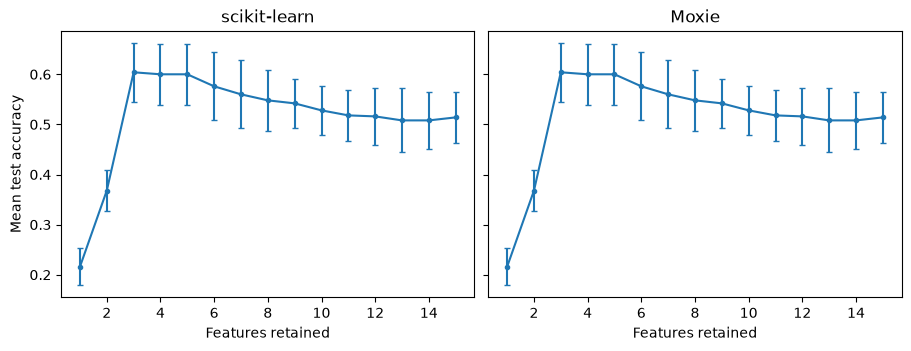

Optimal number of features: 3
Fold 1: feature_3, feature_4, feature_8
Fold 2: feature_3, feature_4, feature_8
Fold 3: feature_3, feature_4, feature_8
Fold 4: feature_3, feature_4, feature_8
Fold 5: feature_3, feature_4, feature_8


In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True, layout="constrained")
for ax, label, results in zip(axes, ("scikit-learn", "Moxie"), (reference.cv_results_, mx)):
    ax.errorbar(results["n_features"], results["mean_test_score"],
                yerr=results["std_test_score"], marker="o", markersize=3, capsize=2)
    ax.set(title=label, xlabel="Features retained")
axes[0].set_ylabel("Mean test accuracy")
plt.show()

selected_row = np.flatnonzero(mx["n_features"] == mx["n_selected"][0]).item()
print("Optimal number of features:", mx["n_selected"][0])
for fold in range(5):
    mask = mx[f"split{fold}_support"][selected_row]
    print(f"Fold {fold + 1}:", ", ".join(feature_names[mask]))